### HW_05

`Input/california_housing.csv`의 `AveOccup`를 분석하여 다음 질문에 답하시오.

- `AveOccup`의 Mean과 Median을 각각 적으시오.
- `AveOccup`의 Histogram을 `bins=30`으로 그렸을 때 가장 많은 Data가 분포하는 구간을 적으시오.
- `AveOccup`의 $Q_1$, $Q_3$, IQR을 각각 적으시오.
- IQR 기준으로 계산한 Outlier의 수를 적으시오.
- `AveOccup`의 가장 큰 값과 해당 Row의 `MedHouseVal`을 적으시오.

답만 제출하시오.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
california_housing_data = pd.read_csv('../Input/california_housing.csv')
AveOccup = california_housing_data['AveOccup']

In [7]:
display(AveOccup.describe())
print(f"Mean AveOccup: {AveOccup.mean()}")
print(f"Median AveOccup: {AveOccup.median()}")


count    20640.000000
mean         3.070655
std         10.386050
min          0.692308
25%          2.429741
50%          2.818116
75%          3.282261
max       1243.333333
Name: AveOccup, dtype: float64

Mean AveOccup: 3.0706551594363742
Median AveOccup: 2.818115654360196


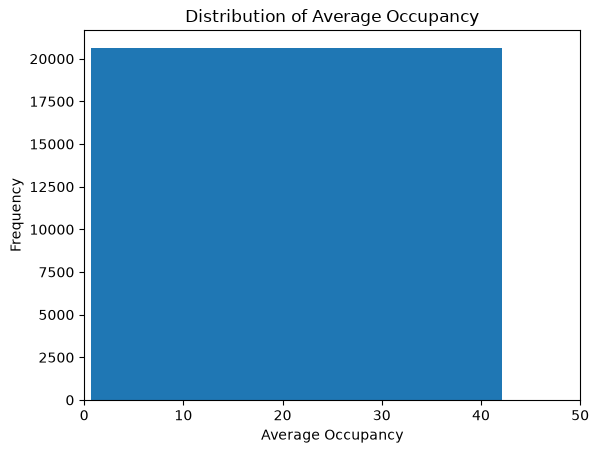

In [8]:
plt.hist(AveOccup, bins=30)
plt.title('Distribution of Average Occupancy')
plt.xlabel('Average Occupancy')
plt.ylabel('Frequency')
plt.xlim(0, 50)
plt.show()

In [9]:
AveOccup.quantile([0.25, 0.5, 0.75])

Q1 = AveOccup.quantile(0.25)
Q3 = AveOccup.quantile(0.75)
IQR = Q3 - Q1

# Outlier 판단 범위 계산
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# 범위를 벗어난 data 확인
outliers = california_housing_data[
    (california_housing_data["AveOccup"] < lower) |
    (california_housing_data["AveOccup"] > upper)
]

outliers_count = outliers.shape[0]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Outliers Count:", outliers_count)
display(outliers)

Q1: 2.4297411475535755
Q3: 3.2822609242736216
IQR: 0.8525197767200461
Lower Bound: 1.1509614824735064
Upper Bound: 4.5610405893536905
Outliers Count: 711


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
89,1.2434,52.0,2.929412,0.917647,396.0,4.658824,37.80,-122.27,5.00001
91,0.8668,52.0,2.443182,0.988636,904.0,10.272727,37.80,-122.28,1.37500
92,0.7500,52.0,2.823529,0.911765,191.0,5.617647,37.80,-122.28,1.62500
200,3.0257,52.0,4.046948,1.009390,994.0,4.666667,37.78,-122.23,0.80800
270,3.8750,33.0,3.021277,0.659574,575.0,12.234043,37.78,-122.18,2.25000
...,...,...,...,...,...,...,...,...,...
20353,5.0066,12.0,3.800000,1.466667,69.0,4.600000,34.13,-119.05,2.75000
20393,5.7560,16.0,6.117493,1.026110,2007.0,5.240209,34.22,-118.88,3.02700
20513,2.6250,34.0,5.597403,1.103896,391.0,5.077922,38.67,-121.63,2.25000
20527,1.4653,7.0,3.525794,1.017857,4479.0,8.886905,38.54,-121.79,3.10000


In [10]:
california_housing_data.sort_values(by="AveOccup", ascending=False).head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
19006,10.2264,45.0,3.166667,0.833333,7460.0,1243.333333,38.32,-121.98,1.375
3364,5.5179,36.0,5.142857,1.142857,4198.0,599.714286,40.41,-120.51,0.675
16669,4.2639,46.0,9.076923,1.307692,6532.0,502.461538,35.32,-120.70,3.500
13034,6.1359,52.0,8.275862,1.517241,6675.0,230.172414,38.69,-121.15,2.250
9172,4.2391,5.0,5.123810,0.933333,8733.0,83.171429,34.47,-118.59,1.546
